# Session 14 — a dense model, upcycled into a Mixture-of-Experts

Session 14 — train a dense model, convert it into a Mixture-of-Experts, keep training.

The assignment: train a (dense/"linear") model, convert it into an MoE, and show both
continue to train and reduce loss. The method here is **sparse upcycling** (Komatsuzaki et
al. 2022): take the trained dense model, replace each feed-forward network with a router + N
copies of that same FFN, and resume training. Because the experts start as identical copies
and the router's top-k weights sum to one, the MoE at step 0 computes *exactly* the dense
output (Section 3 checks this to ~1e-6) — so the loss doesn't jump; it continues falling from
where dense stopped, and now has far more total parameters to keep improving with.

Two things an MoE needs beyond the experts (Section 4):
  * a **router** that scores all experts and keeps the top-k per token, and
  * a **load-balancing** auxiliary loss, or the router collapses onto a few favourites and
    the rest never learn. We log the per-expert load to show it stays balanced.

One source of truth: build_notebook.py splits this into moe_lab.ipynb.

Run:  python moe_lab.py            # writes the plots + results.txt + training_log.txt

> Run top to bottom. We train a dense model, convert it into an 8-expert top-2 MoE by **sparse upcycling**, verify the MoE reproduces the dense output at conversion (so loss continues, no jump), keep training it, and — for contrast — train the same MoE from scratch under an equal budget.

In [1]:
import time
import warnings

import matplotlib

try:
    get_ipython()  # type: ignore # noqa: F821
except NameError:
    matplotlib.use("Agg")
warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

C_BLUE, C_ORANGE, C_GREEN = "#2a78d6", "#eb6834", "#1baf7a"
torch.manual_seed(0)


def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


DEVICE = pick_device()
print(f"device: {DEVICE}")

device: mps


## (1) Data — byte-level language modelling (self-contained, exactly reproducible)

In [2]:
_SEED_TEXT = (
    "A mixture of experts stores many small feed-forward networks and runs only the few the "
    "router picks for each token. Capacity grows with the total parameters; cost per token "
    "grows only with the active ones. Upcycling copies a trained dense network into every "
    "expert, so the sparse model continues exactly where the dense one left off and then "
    "specialises. The router scores every expert, keeps the best few, and a balancing term "
    "keeps the load even so no expert is starved. "
) * 64

VOCAB = 256
raw = _SEED_TEXT.encode("utf-8")
data = torch.tensor(list(raw), dtype=torch.long)
print(f"corpus: {len(data)} bytes, vocab {VOCAB}")


def get_batch(block_size, batch_size, device=DEVICE):
    ix = torch.randint(0, len(data) - block_size - 1, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])
    y = torch.stack([data[i + 1 : i + 1 + block_size] for i in ix])
    return x.to(device), y.to(device)

corpus: 30272 bytes, vocab 256


## (2) The two feed-forward blocks: one dense FFN, one MoE that generalises it


Dense FFN is SwiGLU:  down( SiLU(gate x) * up x ).  An expert is the SAME shape. An MoE
layer keeps N experts + a router; each token uses its top-k experts, combined by the
router's (softmax-normalised) weights. The MoE is a strict generalisation of the dense
FFN: N identical experts with weights summing to one reproduce the dense FFN exactly.

In [3]:
class SwiGLU(nn.Module):
    def __init__(self, d, inner):
        super().__init__()
        self.gate = nn.Linear(d, inner, bias=False)
        self.up = nn.Linear(d, inner, bias=False)
        self.down = nn.Linear(inner, d, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))


class MoE(nn.Module):
    """Router + N SwiGLU experts, top-k routing with a load-balancing auxiliary loss."""

    def __init__(self, d, inner, n_experts, k, aux_coef=0.01):
        super().__init__()
        self.d, self.n_experts, self.k, self.aux_coef = d, n_experts, k, aux_coef
        self.router = nn.Linear(d, n_experts, bias=False)
        self.experts = nn.ModuleList([SwiGLU(d, inner) for _ in range(n_experts)])
        self.last_load = None  # fraction of tokens per expert (for logging)

    def forward(self, x):
        B, T, D = x.shape
        xf = x.reshape(-1, D)                       # (N, D) tokens
        logits = self.router(xf)                    # (N, E)
        probs = F.softmax(logits, dim=-1)           # full distribution (for the aux loss)
        topv, topi = probs.topk(self.k, dim=-1)     # (N, k)
        topw = topv / topv.sum(dim=-1, keepdim=True)  # renormalise chosen weights to sum to 1

        out = torch.zeros_like(xf)
        load = torch.zeros(self.n_experts, device=x.device)
        for e in range(self.n_experts):
            mask = (topi == e)                      # (N, k) where this expert was chosen
            if not mask.any():
                continue
            tok = mask.any(dim=-1)                  # (N,) tokens using expert e
            w = (topw * mask).sum(dim=-1)[tok]      # (n_e,) this expert's weight per token
            out[tok] += w.unsqueeze(-1) * self.experts[e](xf[tok])
            load[e] = tok.float().mean()

        # Switch-Transformer load balance: E * sum_i (f_i * P_i); minimised when both uniform
        f = torch.zeros(self.n_experts, device=x.device)
        onehot = F.one_hot(topi.reshape(-1), self.n_experts).float()
        f = onehot.mean(dim=0)                      # fraction of (token,slot) picks per expert
        P = probs.mean(dim=0)                       # mean router prob per expert
        aux = self.aux_coef * self.n_experts * (f * P).sum()
        self.last_load = load.detach()
        return out.reshape(B, T, D), aux


class Attn(nn.Module):
    def __init__(self, d, n_head):
        super().__init__()
        self.n_head = n_head
        self.qkv = nn.Linear(d, 3 * d)
        self.proj = nn.Linear(d, d)

    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(x).split(D, dim=2)
        q = q.view(B, T, self.n_head, D // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, D // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, D // self.n_head).transpose(1, 2)
        o = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(o.transpose(1, 2).contiguous().view(B, T, D))


class LM(nn.Module):
    """Attention + (dense FFN | MoE) per layer. `moe=False` is the dense baseline."""

    def __init__(self, n_layer, d, n_head, inner, block_size, moe=False,
                 n_experts=8, k=2):
        super().__init__()
        self.block_size, self.is_moe = block_size, moe
        self.tok = nn.Embedding(VOCAB, d)
        self.pos = nn.Embedding(block_size, d)
        self.ln1 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layer)])
        self.ln2 = nn.ModuleList([nn.LayerNorm(d) for _ in range(n_layer)])
        self.attn = nn.ModuleList([Attn(d, n_head) for _ in range(n_layer)])
        if moe:
            self.ff = nn.ModuleList([MoE(d, inner, n_experts, k) for _ in range(n_layer)])
        else:
            self.ff = nn.ModuleList([SwiGLU(d, inner) for _ in range(n_layer)])
        self.lnf = nn.LayerNorm(d)
        self.head = nn.Linear(d, VOCAB, bias=False)
        self.apply(self._init)      # GPT-2-style init: without it the tied-embedding logits
        self.head.weight = self.tok.weight   # are N(0,1)-huge and loss starts in the hundreds

    @staticmethod
    def _init(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.tok(idx) + self.pos(pos)
        aux_total = 0.0
        for i in range(len(self.attn)):
            x = x + self.attn[i](self.ln1[i](x))
            if self.is_moe:
                y, aux = self.ff[i](self.ln2[i](x))
                x = x + y
                aux_total = aux_total + aux
            else:
                x = x + self.ff[i](self.ln2[i](x))
        logits = self.head(self.lnf(x))
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, VOCAB), targets.view(-1))
            if self.is_moe:
                loss = loss + aux_total / len(self.attn)
        return logits, loss


def total_params(m):
    return sum(p.numel() for p in m.parameters()) - m.tok.weight.numel()


def active_params(m, n_layer, d, inner, n_head):
    """Params actually touched per token: attention + k experts (+ router), not all experts."""
    attn = n_layer * (3 * d * d + d + d * d + d)
    if m.is_moe:
        k = m.ff[0].k
        ff = n_layer * (k * 3 * d * inner + d * m.ff[0].n_experts)  # k experts + router
    else:
        ff = n_layer * 3 * d * inner
    return attn + ff

## (3) Upcycling — copy the dense FFN into every expert


Each expert starts as the dense FFN plus a whisper of noise to break symmetry. The router
starts near zero. Because the top-k router weights are renormalised to sum to one and every
expert is (almost) the dense FFN, the MoE's output at step 0 equals the dense output — we
check it. That is why training *continues* instead of restarting.

In [4]:
def upcycle(dense: LM, moe: LM, noise=1e-4):
    moe.load_state_dict(dense.state_dict(), strict=False)  # embeddings, attn, norms, head
    with torch.no_grad():
        for i, moe_layer in enumerate(moe.ff):
            src = dense.ff[i]
            for e in moe_layer.experts:
                e.gate.weight.copy_(src.gate.weight + noise * torch.randn_like(src.gate.weight))
                e.up.weight.copy_(src.up.weight + noise * torch.randn_like(src.up.weight))
                e.down.weight.copy_(src.down.weight + noise * torch.randn_like(src.down.weight))
            moe_layer.router.weight.zero_()  # uniform routing at the start
    return moe


def check_upcycle_equiv(dense, moe, block_size):
    # Does the MoE predict the same as dense at conversion? Compare the cross-entropy computed
    # FROM THE LOGITS (targets=None path) — not model(x, y).loss, which for the MoE adds the
    # load-balance aux term (~0.01) that has nothing to do with the prediction. The CE difference
    # is the true "no jump" number; it averages out the per-logit symmetry-breaking noise.
    dense.eval(); moe.eval()
    x, y = get_batch(block_size, 8)
    with torch.no_grad():
        ld, _ = dense(x)
        lm, _ = moe(x)
        ce_d = F.cross_entropy(ld.reshape(-1, VOCAB), y.reshape(-1))
        ce_m = F.cross_entropy(lm.reshape(-1, VOCAB), y.reshape(-1))
    dense.train(); moe.train()
    return abs(ce_d.item() - ce_m.item())

## (4) Train dense, upcycle, continue; also train MoE-from-scratch for contrast


=== 1. Train the dense model ===


  [dense] step    0/400  loss 5.5946


  [dense] step   16/400  loss 4.2534


  [dense] step   32/400  loss 3.5699


  [dense] step   48/400  loss 2.7789


...

  [moe-scratch] step  352/400  loss 0.0603  load-cv 0.184


  [moe-scratch] step  368/400  loss 0.0636  load-cv 0.170


  [moe-scratch] step  384/400  loss 0.0570  load-cv 0.181


  [moe-scratch] step  399/400  loss 0.0598  load-cv 0.152
  [moe-scratch] done in 254.6s, final loss 0.0598


wrote fig_moe.png

Session 14 — dense -> MoE (sparse upcycling), results
device: mps

config: {'n_layer': 4, 'd': 256, 'n_head': 8, 'inner': 512, 'block_size': 128}, experts=8, top-k=2

Parameter accounting:
  dense : total 2.66M   active/token 2.62M
  MoE   : total 13.68M   active/token 4.20M
  -> MoE has 5.1x the parameters at 1.60x the per-token compute

Upcycling continuity:
  |MoE CE - dense CE| at conversion = 3.35e-05  (same prediction, no jump)

Loss (reduces throughout):
  dense         start 5.5946  final 0.0412
  MoE upcycled  start 0.0512  final 0.0448
  MoE scratch   start 5.5898  final 0.0598

wrote results.txt, training_log.txt


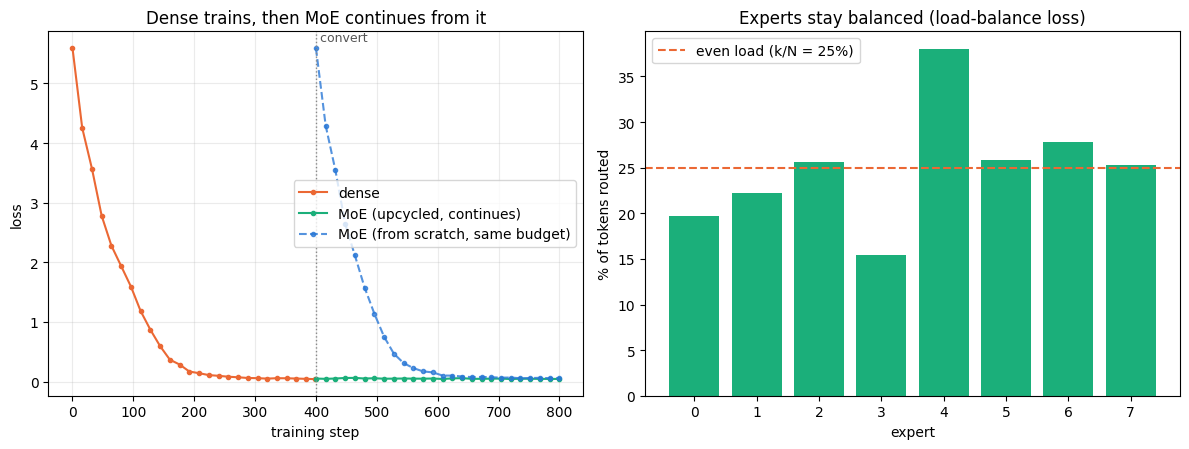

In [5]:
def config():
    # small enough to run locally in minutes; raise on a GPU for a bigger demo
    return dict(n_layer=4, d=256, n_head=8, inner=512, block_size=128)


def train(model, steps, batch, log, tag, color, warmup=50):
    cfg = config()
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, betas=(0.9, 0.95), weight_decay=0.1)
    model.train()
    xs, ys, loads = [], [], []
    t0 = time.time()
    for s in range(steps):
        lr = 3e-4 * min(1.0, (s + 1) / warmup)
        for g in opt.param_groups:
            g["lr"] = lr
        x, y = get_batch(cfg["block_size"], batch)
        _, loss = model(x, y)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        if s % max(1, steps // 25) == 0 or s == steps - 1:
            line = f"[{tag}] step {s:>4}/{steps}  loss {loss.item():.4f}"
            if model.is_moe:
                ld = torch.stack([l.last_load for l in model.ff]).mean(0)
                cv = (ld.std() / (ld.mean() + 1e-9)).item()  # load imbalance (0 = perfect)
                line += f"  load-cv {cv:.3f}"
                loads.append(ld.cpu())
            print("  " + line)
            log.append(line)
            xs.append(s)
            ys.append(loss.item())
    dt = time.time() - t0
    print(f"  [{tag}] done in {dt:.1f}s, final loss {ys[-1]:.4f}")
    return dict(tag=tag, xs=xs, ys=ys, color=color, loads=loads, final=ys[-1])


def run():
    cfg = config()
    log = []
    DENSE_STEPS = 400
    CONT_STEPS = 400
    BATCH = 32

    print("\n=== 1. Train the dense model ===")
    dense = LM(moe=False, **cfg).to(DEVICE)
    r_dense = train(dense, DENSE_STEPS, BATCH, log, "dense", C_ORANGE)

    print("\n=== 2. Upcycle dense -> MoE (8 experts, top-2) and check equivalence ===")
    moe = LM(moe=True, n_experts=8, k=2, **cfg).to(DEVICE)
    moe = upcycle(dense, moe)
    equiv = check_upcycle_equiv(dense, moe, cfg["block_size"])
    msg = f"upcycled MoE vs dense cross-entropy at init: |Δ| = {equiv:.2e} (same output -> no jump)"
    print("  " + msg); log.append(msg)

    print("\n=== 3. Continue training the upcycled MoE ===")
    r_moe = train(moe, CONT_STEPS, BATCH, log, "moe-upcycled", C_GREEN)

    print("\n=== 4. For contrast: train an MoE of the same size FROM SCRATCH ===")
    moe_scratch = LM(moe=True, n_experts=8, k=2, **cfg).to(DEVICE)
    r_scratch = train(moe_scratch, CONT_STEPS, BATCH, log, "moe-scratch", C_BLUE)

    # parameter accounting
    d, inner, nl, nh = cfg["d"], cfg["inner"], cfg["n_layer"], cfg["n_head"]
    tp_dense, ap_dense = total_params(dense), active_params(dense, nl, d, inner, nh)
    tp_moe, ap_moe = total_params(moe), active_params(moe, nl, d, inner, nh)

    # ---- plots ----
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(12, 4.6))
    # left: dense then upcycled-moe on a continuous step axis; scratch overlaid from 0
    axL.plot(r_dense["xs"], r_dense["ys"], "o-", ms=3, color=C_ORANGE, label="dense")
    cont_x = [DENSE_STEPS + s for s in r_moe["xs"]]
    axL.plot(cont_x, r_moe["ys"], "o-", ms=3, color=C_GREEN, label="MoE (upcycled, continues)")
    axL.plot([DENSE_STEPS + s for s in r_scratch["xs"]], r_scratch["ys"], "o--", ms=3,
             color=C_BLUE, alpha=0.8, label="MoE (from scratch, same budget)")
    axL.axvline(DENSE_STEPS, color="#888", ls=":", lw=1)
    axL.text(DENSE_STEPS, axL.get_ylim()[1], " convert", color="#555", va="top", fontsize=9)
    axL.set_xlabel("training step")
    axL.set_ylabel("loss")
    axL.set_title("Dense trains, then MoE continues from it")
    axL.legend()
    axL.grid(alpha=0.25)

    # right: final per-expert load (averaged over layers), last logged
    final_load = r_moe["loads"][-1].numpy()
    bars = axR.bar(range(len(final_load)), final_load * 100, color=C_GREEN)
    axR.axhline(100 * 2 / 8, color=C_ORANGE, ls="--", label="even load (k/N = 25%)")
    axR.set_xlabel("expert")
    axR.set_ylabel("% of tokens routed")
    axR.set_title("Experts stay balanced (load-balance loss)")
    axR.legend()
    fig.tight_layout()
    fig.savefig("fig_moe.png", dpi=120)
    print("wrote fig_moe.png")

    # ---- results.txt ----
    lines = [
        "Session 14 — dense -> MoE (sparse upcycling), results",
        f"device: {DEVICE}",
        "",
        f"config: {cfg}, experts=8, top-k=2",
        "",
        "Parameter accounting:",
        f"  dense : total {tp_dense/1e6:.2f}M   active/token {ap_dense/1e6:.2f}M",
        f"  MoE   : total {tp_moe/1e6:.2f}M   active/token {ap_moe/1e6:.2f}M",
        f"  -> MoE has {tp_moe/tp_dense:.1f}x the parameters at "
        f"{ap_moe/ap_dense:.2f}x the per-token compute",
        "",
        "Upcycling continuity:",
        f"  |MoE CE - dense CE| at conversion = {equiv:.2e}  (same prediction, no jump)",
        "",
        "Loss (reduces throughout):",
        f"  dense         start {r_dense['ys'][0]:.4f}  final {r_dense['final']:.4f}",
        f"  MoE upcycled  start {r_moe['ys'][0]:.4f}  final {r_moe['final']:.4f}",
        f"  MoE scratch   start {r_scratch['ys'][0]:.4f}  final {r_scratch['final']:.4f}",
    ]
    txt = "\n".join(lines)
    with open("results.txt", "w") as f:
        f.write(txt + "\n")
    with open("training_log.txt", "w") as f:
        f.write("\n".join(log) + "\n")
    print("\n" + txt)
    print("\nwrote results.txt, training_log.txt")


if __name__ == "__main__":
    run()